
# 🦟 VectorIA
## Análisis Exploratorio de Datos (EDA)
### Dataset 1: IEEE DataPort – Aedes y Culex

**Proyecto:** VectorIA – Asistente Inteligente para la Vigilancia del Dengue en Costa Rica

**Módulo:** CNN – Identificación de mosquitos

**Dataset:** Image Dataset of Aedes and Culex Mosquito Species

**Fuente:** [IEEE DataPort](https://ieee-dataport.org/open-access/image-dataset-aedes-and-culex-mosquito-species)

---

### Objetivo del análisis

Explorar las características del conjunto de imágenes de mosquitos Aedes y Culex, analizando su distribución por clases, dimensiones, formatos, calidad visual y posibles inconsistencias, con el propósito de identificar aspectos relevantes para el posterior entrenamiento de una red neuronal convolucional (CNN).

---



## 1. Importación de librerías

Se importan las librerías necesarias para la exploración, el análisis estadístico y la visualización de las imágenes del dataset.


In [6]:

# Manejo de archivos y directorios
from pathlib import Path

# Análisis y manipulación de datos
import pandas as pd
import numpy as np

# Visualización de datos
import matplotlib.pyplot as plt

# Procesamiento y análisis de imágenes
from PIL import Image, ImageStat, ImageFilter

# Identificación de archivos duplicados
import hashlib



## 2. Exploración inicial del dataset

Se examina la estructura de directorios del dataset IEEE DataPort para identificar la organización de las imágenes correspondientes a las clases Aedes y Culex.


In [8]:

# Ruta del dataset
ruta = Path("../../../data/raw/mosquitos/IEEE DataPort-Aedes y Culex")

# Mostrar carpetas principales
for carpeta in ruta.iterdir():
    print(carpeta.name)


Aedes
Culex



## 3. Cantidad de imágenes por clase

Se contabiliza el número de imágenes de cada clase para conocer el tamaño del dataset y su distribución.


In [9]:

# Contar imágenes por clase
conteo = {}

for carpeta in ruta.iterdir():
    if carpeta.is_dir():
        imagenes = [
            archivo for archivo in carpeta.rglob("*")
            if archivo.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
        ]
        conteo[carpeta.name] = len(imagenes)

# Mostrar resultados
tabla_conteo = pd.DataFrame(
    conteo.items(),
    columns=["Clase", "Cantidad de imágenes"]
)

display(tabla_conteo)

print("Total de imágenes:", sum(conteo.values()))


,Clase,Cantidad de imágenes
0,Aedes,810
1,Culex,594


Total de imágenes: 1404



## 4. Distribución porcentual de imágenes por clase

Se calcula el porcentaje de imágenes de Aedes y Culex respecto al total del dataset para analizar la proporción de cada clase.


In [10]:

# Calcular porcentaje por clase
tabla_conteo["Porcentaje (%)"] = (
    tabla_conteo["Cantidad de imágenes"]
    / tabla_conteo["Cantidad de imágenes"].sum() * 100
).round(2)

display(tabla_conteo)


,Clase,Cantidad de imágenes,Porcentaje (%)
0,Aedes,810,57.69
1,Culex,594,42.31



## 5. Visualización de imágenes por clase

Se visualizan ejemplos de imágenes de Aedes y Culex para observar sus características visuales, diferencias entre clases y condiciones generales de las fotografías.


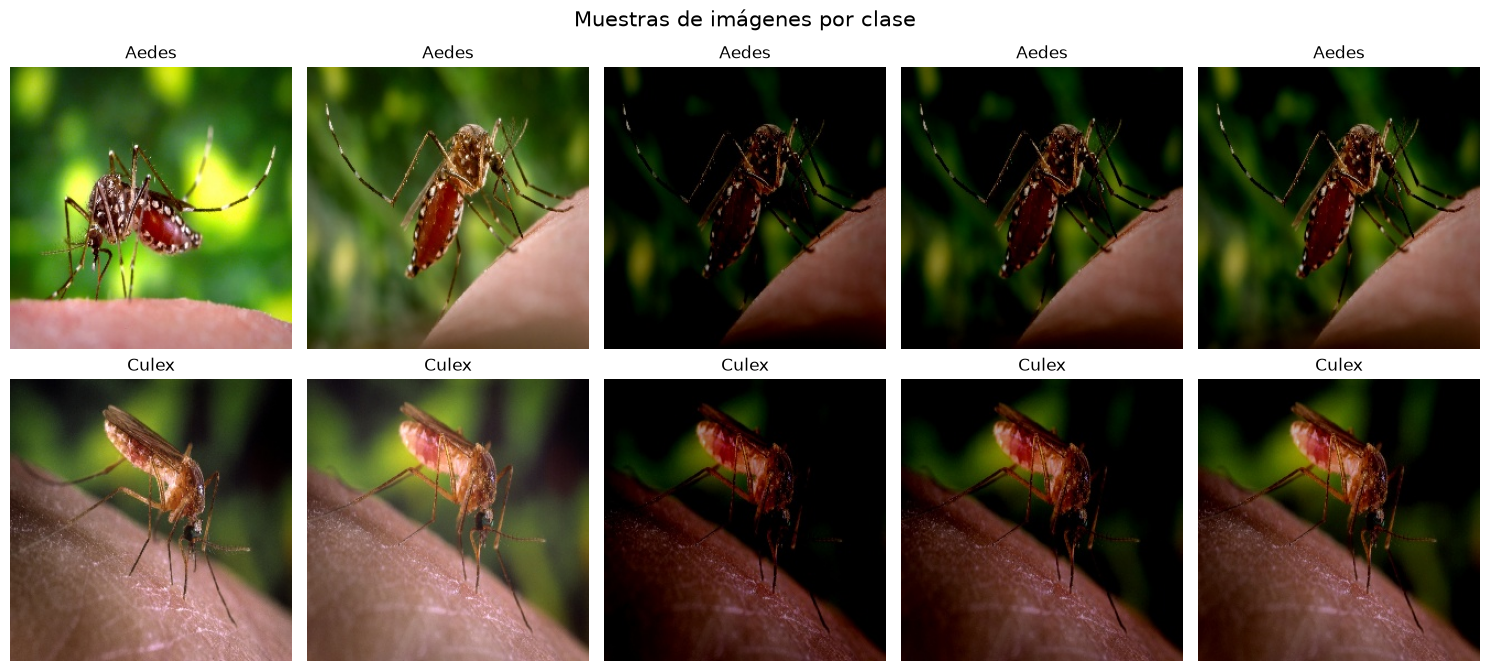

In [12]:

# Mostrar 5 imágenes de cada clase
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for fila, clase in enumerate(["Aedes", "Culex"]):
    imagenes = [
        archivo for archivo in (ruta / clase).rglob("*")
        if archivo.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
    ]

    for columna, archivo in enumerate(imagenes[:5]):
        with Image.open(archivo) as img:
            axes[fila, columna].imshow(img.convert("RGB"))

        axes[fila, columna].set_title(clase)
        axes[fila, columna].axis("off")

plt.suptitle("Muestras de imágenes por clase", fontsize=15)
plt.tight_layout()
plt.show()



## 6. Análisis de dimensiones de las imágenes

Se analizan las dimensiones (ancho y alto) de las imágenes para identificar diferencias de tamaño y determinar si será necesario estandarizarlas antes del entrenamiento de la CNN.


In [13]:

# Obtener las dimensiones de todas las imágenes
dimensiones = []

for clase in ["Aedes", "Culex"]:
    for archivo in (ruta / clase).rglob("*"):
        if archivo.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]:
            with Image.open(archivo) as img:
                ancho, alto = img.size

            dimensiones.append({
                "Clase": clase,
                "Ancho": ancho,
                "Alto": alto
            })

# Crear DataFrame
df_dimensiones = pd.DataFrame(dimensiones)

# Mostrar estadísticas descriptivas
display(df_dimensiones.groupby("Clase")[["Ancho", "Alto"]].describe().round(2))


Ancho                                                  Alto         \
       count   mean  std    min    25%    50%    75%    max  count   mean   
Clase                                                                       
Aedes  810.0  256.0  0.0  256.0  256.0  256.0  256.0  256.0  810.0  256.0   
Culex  594.0  256.0  0.0  256.0  256.0  256.0  256.0  256.0  594.0  256.0   

                                               
       std    min    25%    50%    75%    max  
Clase                                          
Aedes  0.0  256.0  256.0  256.0  256.0  256.0  
Culex  0.0  256.0  256.0  256.0  256.0  256.0


## 7. Análisis de resoluciones diferentes

Se identifican las resoluciones presentes en el dataset y la cantidad de imágenes correspondientes a cada una, con el fin de comprobar la uniformidad de sus dimensiones.


In [14]:

# Contar imágenes por resolución
resoluciones = (
    df_dimensiones
    .groupby(["Ancho", "Alto"])
    .size()
    .reset_index(name="Cantidad")
    .sort_values("Cantidad", ascending=False)
)

display(resoluciones)

print("Total de resoluciones diferentes:", len(resoluciones))


,Ancho,Alto,Cantidad
0,256,256,1404


Total de resoluciones diferentes: 1



## 8. Análisis de formatos de las imágenes

Se identifican los formatos de archivo presentes en el dataset (JPG, PNG, JPEG, entre otros) para comprobar su distribución y compatibilidad con el entrenamiento de la CNN.


In [15]:

# Obtener los formatos de las imágenes
formatos = []

for clase in ["Aedes", "Culex"]:
    for archivo in (ruta / clase).rglob("*"):
        if archivo.is_file():
            formatos.append({
                "Clase": clase,
                "Formato": archivo.suffix.lower()
            })

# Crear DataFrame
df_formatos = pd.DataFrame(formatos)

# Contar archivos por formato y clase
tabla_formatos = pd.crosstab(
    df_formatos["Formato"],
    df_formatos["Clase"],
    margins=True
)

display(tabla_formatos)


Clase,Aedes,Culex,All
Formato,,,
.jpg,810,594,1404
All,810,594,1404



## 9. Análisis de canales de color

Se identifican los modos de color de las imágenes (RGB, RGBA y escala de grises) para determinar si existe uniformidad y si será necesario realizar conversiones antes del entrenamiento de la CNN.


In [16]:


# Identificar los modos de color
modos_color = []

for clase in ["Aedes", "Culex"]:
    for archivo in (ruta / clase).rglob("*"):
        if archivo.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]:
            with Image.open(archivo) as img:
                modos_color.append({
                    "Clase": clase,
                    "Modo": img.mode
                })

# Crear DataFrame
df_colores = pd.DataFrame(modos_color)

# Mostrar cantidad de imágenes por modo de color
tabla_colores = pd.crosstab(
    df_colores["Modo"],
    df_colores["Clase"],
    margins=True
)

display(tabla_colores)


Clase,Aedes,Culex,All
Modo,,,
RGB,810,594,1404
All,810,594,1404



## 10. Análisis de brillo de las imágenes

Se calcula el brillo promedio de las imágenes de Aedes y Culex para identificar diferencias de iluminación y detectar fotografías demasiado oscuras o claras que podrían afectar el entrenamiento de la CNN.


,count,mean,std,min,25%,50%,75%,max
Clase,,,,,,,,
Aedes,810.0,114.15,47.26,4.44,87.50,109.96,141.95,248.88
Culex,594.0,105.80,50.86,5.79,70.31,99.02,134.24,251.47


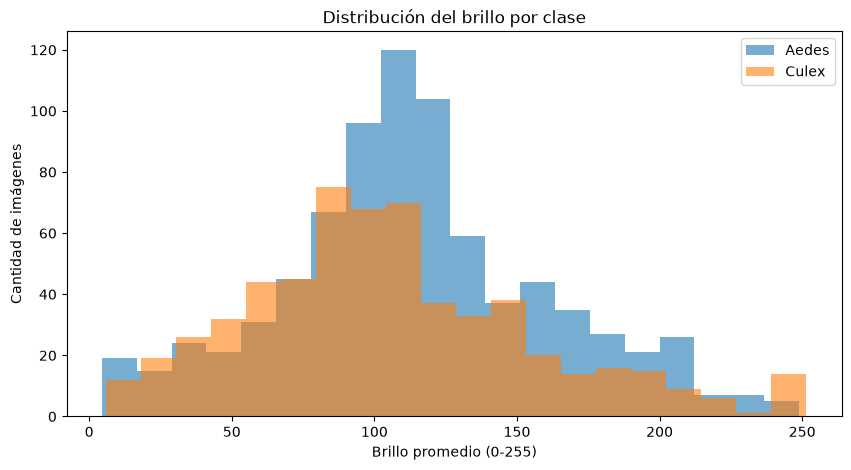

In [18]:

# Calcular el brillo promedio de cada imagen
brillos = []

for clase in ["Aedes", "Culex"]:
    for archivo in (ruta / clase).rglob("*"):
        if archivo.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]:
            with Image.open(archivo) as img:
                imagen_gris = img.convert("L")
                brillo = ImageStat.Stat(imagen_gris).mean[0]

            brillos.append({
                "Clase": clase,
                "Brillo": brillo
            })

# Crear DataFrame
df_brillos = pd.DataFrame(brillos)

# Estadísticas descriptivas por clase
display(df_brillos.groupby("Clase")["Brillo"].describe().round(2))

# Visualizar distribución del brillo
plt.figure(figsize=(10, 5))

for clase in ["Aedes", "Culex"]:
    plt.hist(
        df_brillos[df_brillos["Clase"] == clase]["Brillo"],
        bins=20,
        alpha=0.6,
        label=clase
    )

plt.xlabel("Brillo promedio (0-255)")
plt.ylabel("Cantidad de imágenes")
plt.title("Distribución del brillo por clase")
plt.legend()
plt.show()



## 11. Análisis de calidad visual de las imágenes

Se evalúa la nitidez de las imágenes mediante la varianza del filtro Laplaciano, con el objetivo de identificar fotografías potencialmente borrosas que podrían dificultar el entrenamiento de la CNN.


,count,mean,std,min,25%,50%,75%,max
Clase,,,,,,,,
Aedes,810.0,934.95,470.42,4.41,669.51,928.35,1163.30,3053.36
Culex,594.0,929.53,570.77,115.15,542.96,775.34,1132.92,3761.50


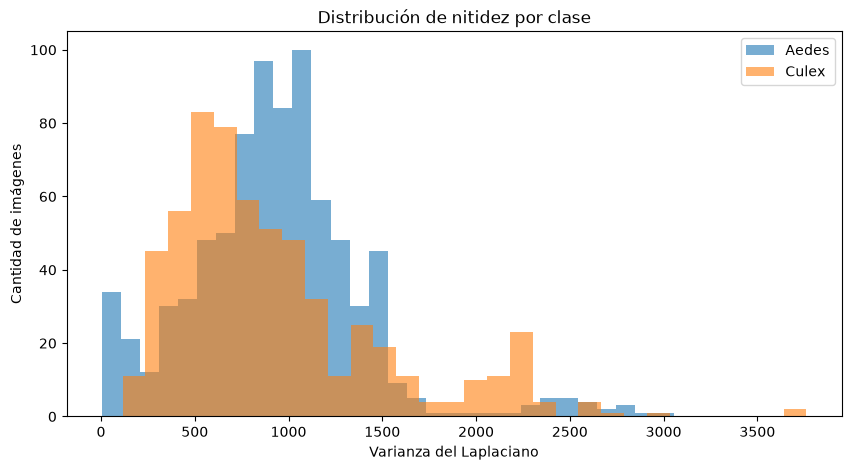

In [22]:

import cv2

# Calcular nitidez de las imágenes
nitidez = []

for clase in ["Aedes", "Culex"]:
    for archivo in (ruta / clase).rglob("*"):
        if archivo.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]:
            with Image.open(archivo) as img:
                imagen = np.array(img.convert("L"))

            laplaciano = cv2.Laplacian(imagen, cv2.CV_64F)
            valor_nitidez = laplaciano.var()

            nitidez.append({
                "Clase": clase,
                "Nitidez": valor_nitidez
            })

# Crear DataFrame
df_nitidez = pd.DataFrame(nitidez)

# Estadísticas descriptivas
display(df_nitidez.groupby("Clase")["Nitidez"].describe().round(2))

# Distribución de nitidez
plt.figure(figsize=(10, 5))

for clase in ["Aedes", "Culex"]:
    plt.hist(
        df_nitidez[df_nitidez["Clase"] == clase]["Nitidez"],
        bins=30,
        alpha=0.6,
        label=clase
    )

plt.xlabel("Varianza del Laplaciano")
plt.ylabel("Cantidad de imágenes")
plt.title("Distribución de nitidez por clase")
plt.legend()
plt.show()



## 12. Detección de imágenes duplicadas

Se identifican imágenes exactamente duplicadas mediante el algoritmo SHA-256, con el objetivo de detectar archivos repetidos que podrían afectar la distribución de los datos y la evaluación de la CNN.


In [23]:

# Identificar imágenes duplicadas mediante SHA-256
hashes = {}
duplicados = []

for clase in ["Aedes", "Culex"]:
    for archivo in (ruta / clase).rglob("*"):
        if archivo.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]:

            with open(archivo, "rb") as imagen:
                hash_imagen = hashlib.sha256(imagen.read()).hexdigest()

            if hash_imagen in hashes:
                duplicados.append({
                    "Clase": clase,
                    "Archivo": archivo.name,
                    "Original": str(hashes[hash_imagen])
                })
            else:
                hashes[hash_imagen] = archivo

# Resultados
df_duplicados = pd.DataFrame(duplicados)

print("Total de imágenes analizadas:", len(hashes) + len(duplicados))
print("Imágenes duplicadas:", len(duplicados))
print("Imágenes únicas:", len(hashes))

display(df_duplicados.head(10))


Total de imágenes analizadas: 1404
Imágenes duplicadas: 52
Imágenes únicas: 1352


,Clase,Archivo,Original
0,Aedes,Aedes10_shear2.jpg,..\..\..\data\raw\mosquitos\IEEE DataPort-Aede...
1,Aedes,Aedes11_shear2.jpg,..\..\..\data\raw\mosquitos\IEEE DataPort-Aede...
2,Aedes,Aedes12_shear2.jpg,..\..\..\data\raw\mosquitos\IEEE DataPort-Aede...
3,Aedes,Aedes13_shear2.jpg,..\..\..\data\raw\mosquitos\IEEE DataPort-Aede...
4,Aedes,Aedes15_shear2.jpg,..\..\..\data\raw\mosquitos\IEEE DataPort-Aede...
5,Aedes,Aedes16_shear2.jpg,..\..\..\data\raw\mosquitos\IEEE DataPort-Aede...
6,Aedes,Aedes17_shear2.jpg,..\..\..\data\raw\mosquitos\IEEE DataPort-Aede...
7,Aedes,Aedes18_shear2.jpg,..\..\..\data\raw\mosquitos\IEEE DataPort-Aede...
8,Aedes,Aedes19_shear2.jpg,..\..\..\data\raw\mosquitos\IEEE DataPort-Aede...
9,Aedes,Aedes1_shear2.jpg,..\..\..\data\raw\mosquitos\IEEE DataPort-Aede...



## 13. Detección de archivos dañados

Se verifica la integridad de las imágenes del dataset para identificar archivos corruptos o que no puedan abrirse correctamente, los cuales podrían provocar errores durante el entrenamiento de la CNN.


In [24]:

# Identificar imágenes dañadas
archivos_danados = []
total_revisados = 0

for clase in ["Aedes", "Culex"]:
    for archivo in (ruta / clase).rglob("*"):
        if archivo.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]:
            total_revisados += 1

            try:
                with Image.open(archivo) as img:
                    img.verify()

                with Image.open(archivo) as img:
                    img.load()

            except Exception as e:
                archivos_danados.append({
                    "Clase": clase,
                    "Archivo": archivo.name,
                    "Error": str(e)
                })

# Mostrar resultados
df_danados = pd.DataFrame(archivos_danados)

print("Imágenes revisadas:", total_revisados)
print("Imágenes dañadas:", len(archivos_danados))
print("Imágenes válidas:", total_revisados - len(archivos_danados))

display(df_danados)


Imágenes revisadas: 1404
Imágenes dañadas: 0
Imágenes válidas: 1404


""



## 14. Análisis del desbalance de clases

Se analiza la distribución de imágenes entre Aedes y Culex para determinar el grado de desbalance del dataset y su posible influencia en el entrenamiento de la CNN.


,Clase,Cantidad de imágenes,Porcentaje (%)
0,Aedes,810,57.69
1,Culex,594,42.31


Relación de desbalance: 1.36:1


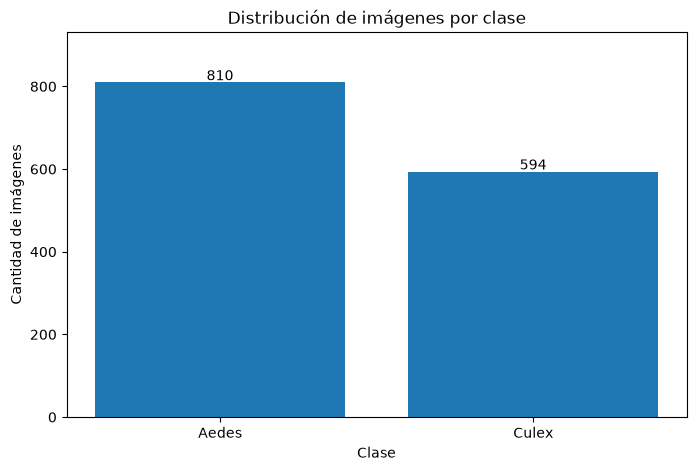

In [25]:

# Calcular cantidad y porcentaje por clase
distribucion = tabla_conteo.copy()

# Calcular relación entre la clase mayoritaria y minoritaria
mayor = distribucion["Cantidad de imágenes"].max()
menor = distribucion["Cantidad de imágenes"].min()

relacion = mayor / menor

# Mostrar resultados
display(distribucion)

print(f"Relación de desbalance: {relacion:.2f}:1")

# Gráfico de distribución por clase
plt.figure(figsize=(8, 5))

barras = plt.bar(
    distribucion["Clase"],
    distribucion["Cantidad de imágenes"]
)

plt.title("Distribución de imágenes por clase")
plt.xlabel("Clase")
plt.ylabel("Cantidad de imágenes")

for barra in barras:
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 5,
        str(int(barra.get_height())),
        ha="center"
    )

plt.ylim(0, mayor * 1.15)
plt.show()



## 15. Conclusiones generales del EDA

El análisis exploratorio del dataset IEEE DataPort permitió identificar las principales características de las imágenes de mosquitos Aedes y Culex, así como posibles aspectos que deben considerarse antes del entrenamiento de la CNN.

### 15.1. Principales hallazgos

1. **Cantidad de imágenes:** se analizaron 1.404 imágenes, distribuidas en 810 de Aedes (57,69 %) y 594 de Culex (42,31 %).

2. **Desbalance de clases:** se identificó una relación de 1,36:1, lo que representa un desbalance leve. Aunque no parece crítico, podría influir en la clasificación de la clase minoritaria.

3. **Dimensiones:** todas las imágenes presentan una resolución uniforme de 256 × 256 píxeles, sin variaciones entre las clases.

4. **Iluminación:** las imágenes presentan distintos niveles de brillo, con mayor concentración aproximadamente entre 70 y 130. Existen fotografías considerablemente oscuras y otras muy claras.

5. **Nitidez:** ambas clases presentan variabilidad en los niveles de nitidez. Algunas imágenes obtuvieron valores bajos de varianza del Laplaciano, lo que podría indicar desenfoque.

6. **Imágenes duplicadas:** se identificaron 52 archivos exactamente duplicados (3,70 %), quedando 1.352 imágenes únicas.

7. **Integridad:** las 1.404 imágenes se pudieron abrir y leer correctamente, sin detectar archivos dañados.

### 15.2. Recomendaciones para el entrenamiento

- Eliminar los 52 duplicados exactos, verificando previamente sus etiquetas.
- Revisar visualmente las imágenes con valores extremos de brillo y nitidez.
- Redimensionar las imágenes a 128 × 128 píxeles según la arquitectura CNN propuesta.
- Considerar el desbalance de clases y evaluar el rendimiento individual de Aedes y Culex.
- Evitar que imágenes originales y sus versiones aumentadas se distribuyan entre entrenamiento y prueba, para prevenir fugas de información.
- Combinar este dataset con otras fuentes para obtener las especies específicas que requiere VectorIA.

### 15.3. Conclusión final

El dataset IEEE DataPort presenta condiciones favorables para el entrenamiento de una CNN, debido a su uniformidad dimensional y ausencia de archivos dañados.

Sin embargo, se identificaron imágenes duplicadas, diferencias de iluminación y nitidez, y un ligero desbalance entre clases. Estos aspectos deben considerarse durante la preparación de los datos.

Además, el dataset distingue Aedes y Culex, pero no permite identificar directamente las tres clases específicas requeridas por VectorIA: Aedes aegypti, Aedes albopictus y Culex. Por ello, será necesario complementarlo con los demás datasets del proyecto y revisar la compatibilidad de sus etiquetas.
